[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/14_stochastic_em.py)

# Stochastic EM, Deterministic Annealing, and SAEM

Plain EM only climbs: from a bad starting point it converges to the nearest local optimum, and the hard assignments of CEM make this worse. This notebook compares four ways of fitting from the *same* deliberately bad initialization: standard EM and CEM, and three variants that add randomness or smoothing -- `algorithm='sem'` (Stochastic EM, Celeux & Diebolt 1985), `temperature` (Deterministic Annealing EM, Ueda & Nakano 1998) and `algorithm='saem'` (Stochastic Approximation EM, Delyon, Lavielle & Moulines 1999).

**What you'll learn**

- how a saddle initialization traps EM and CEM at a poor local optimum
- how SEM (sampling a hard assignment from the responsibilities each sweep) and DAEM (tempering the E-step) escape it
- why SEM's log-likelihood trace never settles to a point but to a "stationary band"
- how SAEM adds a decaying step size so it converges like ordinary EM

**Prerequisites:** [02 -- EM Algorithm](02_em_algorithm.ipynb), [04 -- CEM](04_cem.ipynb).
See also the [Fitting Algorithms](../user-guide/gaussian-mixture.md#fitting-algorithms) section of the Gaussian Mixture Model user guide.

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from tgmm import GaussianMixture

device = 'cuda' if torch.cuda.is_available() else 'cpu'
plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; marimo embeds figures at 2x, so keep outputs small
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f'Using device: {device}')

Using device: cpu


## A known saddle initialization

Three well-separated true clusters, but all three components are initialized jittered around a
*single* one of them (cluster 0) -- a classic EM failure mode: two components end up fighting
over the one cluster they started near, while the third true cluster is left with no component
to claim it. Standard (soft) EM and CEM both get stuck here; SEM's stochastic sampling and DAEM's
tempered E-step both escape it, as shown below.

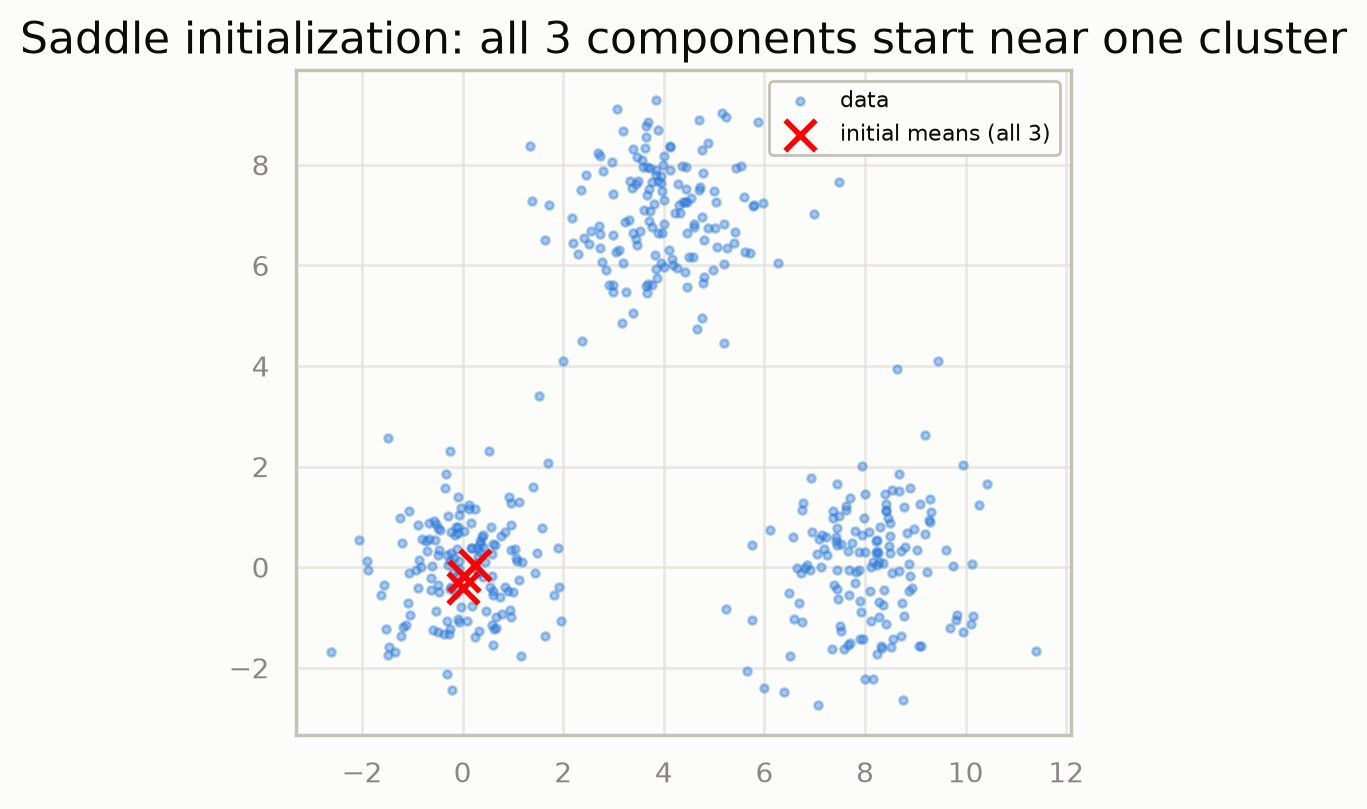

In [ ]:
torch.manual_seed(0)
centers = [(0.0, 0.0), (8.0, 0.0), (4.0, 7.0)]
X = torch.cat([torch.randn(150, 2) + torch.tensor(c) for c in centers])

torch.manual_seed(3)
init_means = torch.tensor([0.0, 0.0]).unsqueeze(0).repeat(3, 1) + torch.randn(3, 2) * 0.3
init_covariances = torch.stack([torch.eye(2)] * 3)

plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], s=8, alpha=0.4, label='data')
plt.scatter(init_means[:, 0], init_means[:, 1], c='red', marker='x', s=120, label='initial means (all 3)')
plt.legend()
plt.title('Saddle initialization: all 3 components start near one cluster')
plt.gca().set_aspect('equal')
plt.gcf()

## Fit EM, CEM, SEM, and DAEM from the identical initialization

In [ ]:
common_kwargs = dict(
    n_components=3, n_features=2, random_state=SEED, max_iter=100,
    init_means=init_means.clone(), init_covariances=init_covariances.clone(),
)

gmm_em = GaussianMixture(algorithm='em', **common_kwargs)
gmm_em.fit(X)

gmm_cem = GaussianMixture(algorithm='cem', **common_kwargs)
gmm_cem.fit(X)

gmm_sem = GaussianMixture(algorithm='sem', **common_kwargs)
gmm_sem.fit(X)

gmm_daem = GaussianMixture(temperature=(0.9, 30), **common_kwargs)
gmm_daem.fit(X)

for _name, _gmm in [('EM', gmm_em), ('CEM', gmm_cem), ('SEM', gmm_sem), ('DAEM', gmm_daem)]:
    print(f'{_name:5s} final log-likelihood: {_gmm.lower_bound_:.4f}')

EM    final log-likelihood: -4.4467
CEM   final log-likelihood: -4.4475
SEM   final log-likelihood: -3.9811
DAEM  final log-likelihood: -3.9810


## Log-likelihood traces, plotted together

EM and CEM plateau early, stuck at the same (worse) local optimum. SEM
climbs to the *better* optimum and stays there; unlike EM it never stops, and at this scale its
tail looks flat, but it actually keeps fluctuating in a narrow "stationary band" (zoomed in below),
since every iteration re-samples a hard assignment instead of converging to a fixed point. DAEM's trace shows the tempered,
lower-likelihood early iterations (while `beta < 1`) before it locks onto the better solution as
`beta` reaches `1.0`.

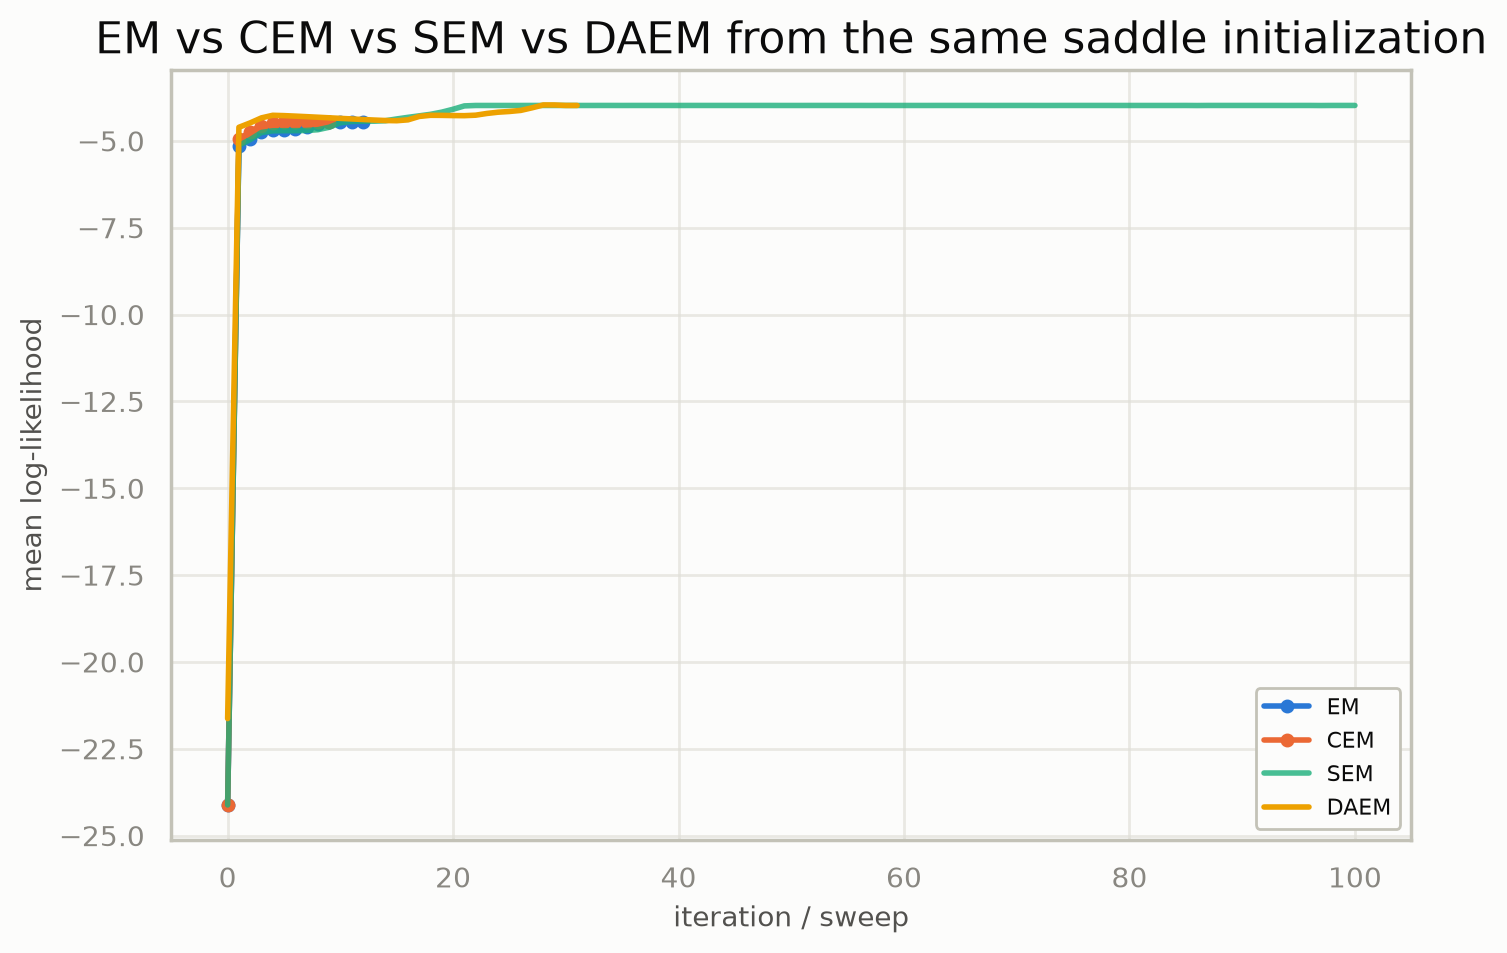

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(gmm_em.log_likelihood_history_, label='EM', marker='.')
plt.plot(gmm_cem.log_likelihood_history_, label='CEM', marker='.')
plt.plot(gmm_sem.log_likelihood_history_, label='SEM', alpha=0.8)
plt.plot(gmm_daem.log_likelihood_history_, label='DAEM', linewidth=2)
plt.xlabel('iteration / sweep')
plt.ylabel('mean log-likelihood')
plt.title('EM vs CEM vs SEM vs DAEM from the same saddle initialization')
plt.legend()
plt.gcf()

### Zooming in: SEM's stationary band

Unlike EM/CEM/DAEM, SEM never converges pointwise -- `fit()` always runs the full `max_iter`
sweeps (see `algorithm='sem'`'s docstring). The tail of its trace fluctuates in a narrow band
around the best achievable log-likelihood instead of settling exactly, since each sweep samples a
fresh hard assignment from the responsibilities rather than taking the `argmax`.

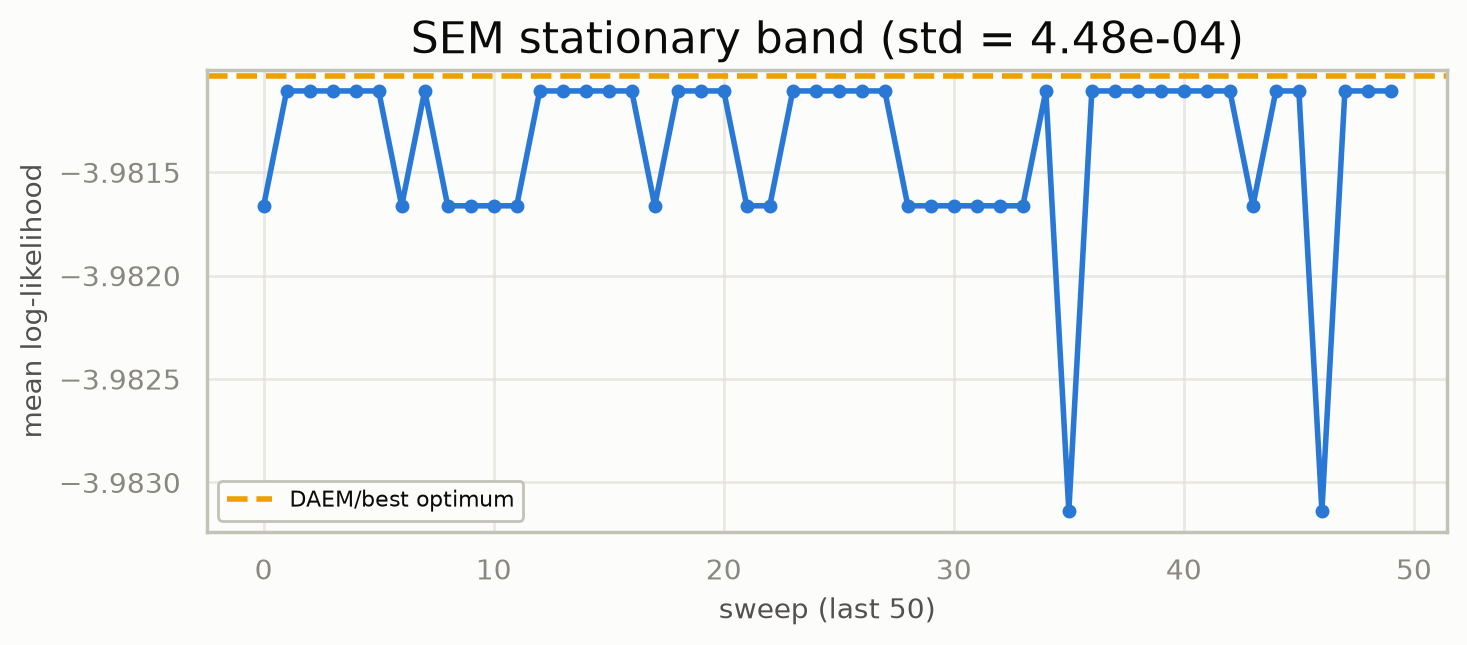

In [ ]:
_tail = gmm_sem.log_likelihood_history_[-50:]
plt.figure(figsize=(8, 3))
plt.plot(_tail, marker='.')
plt.axhline(gmm_daem.lower_bound_, color='C3', linestyle='--', label='DAEM/best optimum')
plt.xlabel('sweep (last 50)')
plt.ylabel('mean log-likelihood')
plt.title(f'SEM stationary band (std = {_tail.std().item():.2e})')
plt.legend()
plt.gcf()

`n_empty_components_` counts how many times a component emptied out and had to be re-seeded
during the run -- a non-zero count is a hint that `n_components` may be larger than the data
supports.

In [ ]:
print('n_empty_components_:', gmm_sem.n_empty_components_)
print('annealing_schedule_ (first 10 values):', gmm_daem.annealing_schedule_[:10])

n_empty_components_: 0
annealing_schedule_ (first 10 values): [0.9, 0.9031663723922961, 0.9063438846891775, 0.9095325760829622, 0.9127324859038545, 0.9159436536204298, 0.9191661188401216, 0.9223999213097097, 0.9256451009158111, 0.928901697685371]


## SAEM: the "SEM that converges"

SAEM blends each sweep's sampled-assignment statistics into a running average with a decaying
step size (`step_size`, defaulting to `'auto'` for this algorithm), so -- unlike plain SEM --
`tol`-based convergence applies and `fit()` can stop early. Demonstrated on a fresh,
well-separated dataset here rather than continuing with the adversarial initialization above:
SAEM's own stochastic trajectory from that specific saddle point happens to settle into a
*different*, also-mediocre local optimum (not shown) -- a reminder that none of these methods
*guarantee* escaping every bad initialization, they each just change the odds. What SAEM
reliably does is match plain EM when both are given the same, reasonable starting point -- here two moderately overlapping clusters, started from the default k-means initialization:

EM means:
 tensor([[ 0.0230,  0.0149],
        [ 3.0272, -0.0422]])
SAEM means:
 tensor([[ 0.0148,  0.0141],
        [ 3.0403, -0.0415]])
SAEM converged: True, iterations: 3


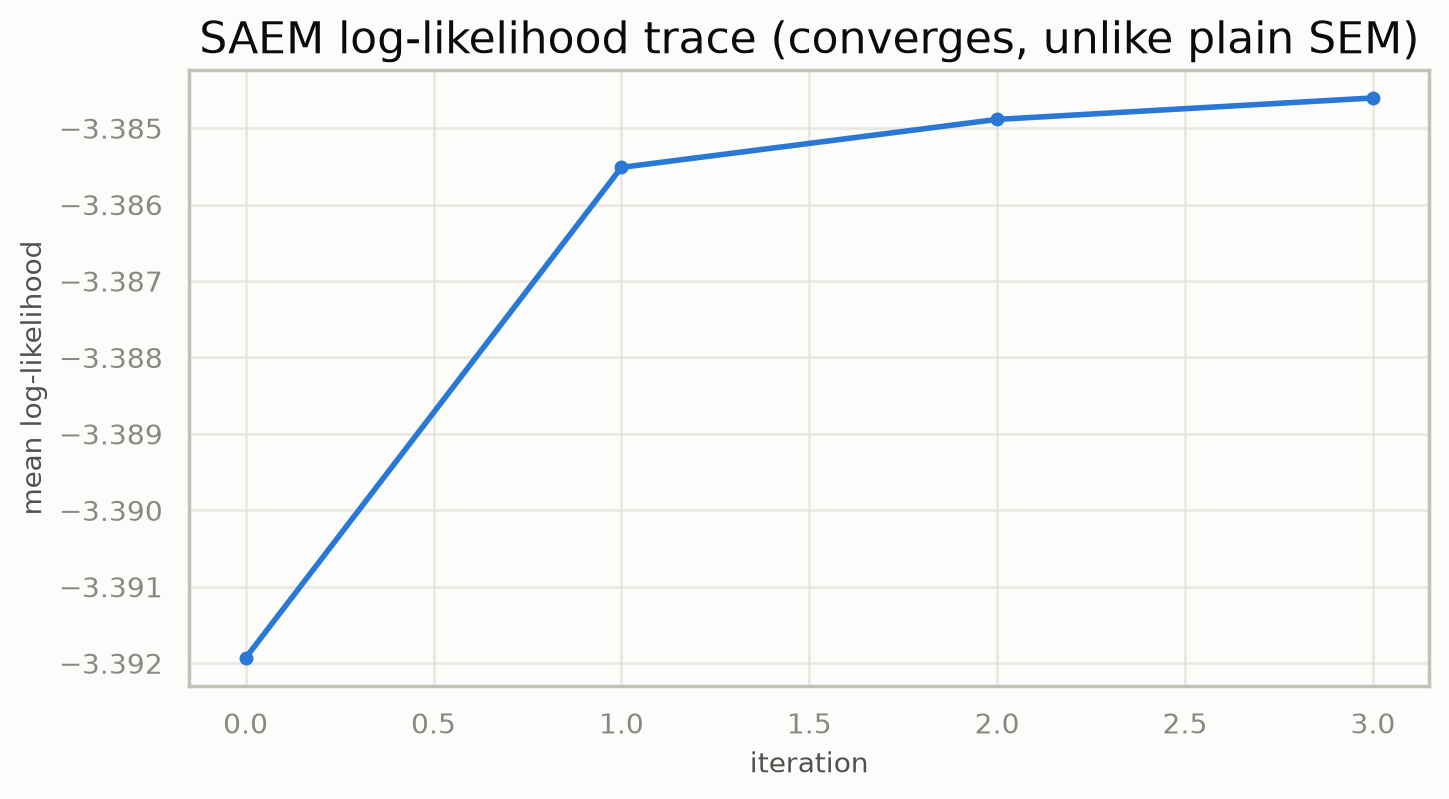

In [ ]:
torch.manual_seed(1)
X2 = torch.cat([torch.randn(2000, 2) + c for c in
                [torch.tensor([0.0, 0.0]), torch.tensor([3.0, 0.0])]])

gmm_em2 = GaussianMixture(n_components=2, n_features=2, algorithm='em', random_state=0, max_iter=200)
gmm_em2.fit(X2)

gmm_saem2 = GaussianMixture(n_components=2, n_features=2, algorithm='saem', random_state=0, max_iter=200)
gmm_saem2.fit(X2)

print('EM means:\n', gmm_em2.means_)
print('SAEM means:\n', gmm_saem2.means_)
print(f'SAEM converged: {gmm_saem2.converged_}, iterations: {gmm_saem2.n_iter_}')

plt.figure(figsize=(8, 4))
plt.plot(gmm_saem2.log_likelihood_history_, marker='.')
plt.xlabel('iteration')
plt.ylabel('mean log-likelihood')
plt.title('SAEM log-likelihood trace (converges, unlike plain SEM)')
plt.gcf()

## Summary

- **EM** (default) and **CEM** (hard assignments) both converge to the nearest local optimum, so from the saddle initialization they stay stuck.
- **SEM** escapes by sampling hard assignments instead of taking the `argmax`, at the cost of never settling to a single point -- use `sem_estimate='best'` or `'mean'` over the post-burn-in sweeps to get a final answer out of a noisy trace.
- **DAEM** escapes by tempering the E-step early on, smoothing the likelihood surface while the fit is still deciding where to settle.
- **SAEM** gets SEM's exploration with a decaying step size, so it converges like ordinary EM and matches EM closely from a reasonable initialization.
- None of these *guarantee* escaping every bad initialization; they change the odds.

**Next:** [15 -- Covariance Structures](15_covariance_models.ipynb). Mini-batch and online EM (`batch_size` / `step_size`), which are not shown here, are covered in the [Fitting Algorithms](../user-guide/gaussian-mixture.md#fitting-algorithms) section of the user guide.